# Ch5：基于视觉的目标识别

按顺序运行下方单元格。第 1 格集中设置相机、ROI、面积阈值和 HSV 初值；第 3 格只用合成图做离线自检；第 4 格读取一次真实摄像头画面；第 5 格提供实时识别与取证按钮。所有真实截图和 CSV 行仅由摄像头实际画面产生，HSV 初值必须现场校准后才能写入报告。

若第 4 格取帧超时，先检查摄像头、USB 连接和供电，待设备能输出真实画面后再继续。不要把离线自检结果当作真机测试。

In [1]:
from pathlib import Path
from datetime import datetime
import csv
import threading
import time

import cv2
import numpy as np
import ipywidgets as widgets
from IPython.display import display, Image

# 现场调参区：相机、ROI、面积阈值和 HSV 范围均在此修改。
PROJECT_DIR = Path.cwd()
if PROJECT_DIR.name != "5.目标识别" and (PROJECT_DIR / "5.目标识别").is_dir():
    PROJECT_DIR = PROJECT_DIR / "5.目标识别"
EVIDENCE_DIR = PROJECT_DIR / "evidence"
RECORD_CSV = PROJECT_DIR / "week5_test_records.csv"
CAMERA_DEVICE = 0  # 重启后当前设备为 /dev/video0；若设备号变化，在此修改。
# 沿用第 3 章已验证的打开方式，不强制改写摄像头分辨率、帧率或格式。
ROI = None  # 识别整幅画面；如需限定范围，可改为 (x, y, 宽, 高)。
MIN_AREA = 700
KERNEL_SIZE = 5
COLOR_ORDER = ("red", "yellow", "green", "blue")
COLOR_NAMES = {"red": "红", "yellow": "黄", "green": "绿", "blue": "蓝"}
COLOR_CONFIG = {
    # 红色跨越 OpenCV 的 H=0/179 边界，必须保留两段。
    "red": {"bgr": (0, 0, 255), "intervals": (((0, 90, 70), (10, 255, 255)), ((170, 90, 70), (179, 255, 255)))},
    "yellow": {"bgr": (0, 255, 255), "intervals": (((18, 80, 80), (38, 255, 255)),)},
    # 白色背景下绿色方块正面 V 约为 40～48，现场将下限从 50 降到 35。
    "green": {"bgr": (0, 255, 0), "intervals": (((40, 60, 35), (90, 255, 255)),)},
    "blue": {"bgr": (255, 0, 0), "intervals": (((95, 80, 50), (135, 255, 255)),)},
}
print("项目目录：", PROJECT_DIR)
print("相机设备：/dev/video{}；ROI：{}；最小面积：{}".format(CAMERA_DEVICE, ROI, MIN_AREA))
for name in COLOR_ORDER:
    print("{}色 HSV 初值：{}".format(COLOR_NAMES[name], COLOR_CONFIG[name]["intervals"]))

项目目录： d:\robot\5.目标识别
相机设备：/dev/video0；ROI：None；最小面积：700
红色 HSV 初值：(((0, 90, 70), (10, 255, 255)), ((170, 90, 70), (179, 255, 255)))
黄色 HSV 初值：(((18, 80, 80), (38, 255, 255)),)
绿色 HSV 初值：(((40, 60, 35), (90, 255, 255)),)
蓝色 HSV 初值：(((95, 80, 50), (135, 255, 255)),)


## 识别与取证函数

本格只定义函数，不打开摄像头。

In [2]:
def open_camera():
    """按第 3 章示例打开摄像头，不强制写入设备属性。"""
    capture = cv2.VideoCapture(CAMERA_DEVICE)
    if not capture.isOpened():
        capture.release()
        raise RuntimeError("无法打开摄像头 /dev/video{}，请检查设备号和连接。".format(CAMERA_DEVICE))
    return capture


def read_camera_frame(capture):
    """读取真实画面；取帧失败时指出设备排查命令。"""
    ok, frame = capture.read()
    if not ok or frame is None:
        raise RuntimeError(
            "摄像头 /dev/video{} 已打开但未输出画面。请在终端运行 "
            "v4l2-ctl -d /dev/video{} --stream-mmap=3 --stream-count=3；"
            "若此前强制修改过宽高，请拔插摄像头后重试。".format(CAMERA_DEVICE, CAMERA_DEVICE)
        )
    return frame


def crop_roi(frame):
    """返回 ROI 图像和相对原图的坐标偏移。"""
    if ROI is None:
        return frame, 0, 0
    x, y, width, height = ROI
    frame_height, frame_width = frame.shape[:2]
    if x < 0 or y < 0 or width <= 0 or height <= 0 or x + width > frame_width or y + height > frame_height:
        raise ValueError("ROI {} 超出 {}x{} 摄像头画面。".format(ROI, frame_width, frame_height))
    return frame[y:y + height, x:x + width], x, y


def detect_colors(frame):
    """返回标注图、四类掩膜和真实画面中的检测结果。"""
    cropped, offset_x, offset_y = crop_roi(frame)
    hsv = cv2.cvtColor(cropped, cv2.COLOR_BGR2HSV)
    kernel = np.ones((KERNEL_SIZE, KERNEL_SIZE), np.uint8)
    annotated = frame.copy()
    masks = {}
    detections = []
    for name in COLOR_ORDER:
        spec = COLOR_CONFIG[name]
        mask = np.zeros(hsv.shape[:2], dtype=np.uint8)
        for lower, upper in spec["intervals"]:
            mask = cv2.bitwise_or(mask, cv2.inRange(hsv, np.array(lower, dtype=np.uint8), np.array(upper, dtype=np.uint8)))
        mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
        mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
        masks[name] = mask
        contours = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[-2]
        for contour in contours:
            area = float(cv2.contourArea(contour))
            if area < MIN_AREA:
                continue
            x, y, width, height = cv2.boundingRect(contour)
            left, top = x + offset_x, y + offset_y
            center = (left + width // 2, top + height // 2)
            cv2.rectangle(annotated, (left, top), (left + width, top + height), spec["bgr"], 2)
            cv2.circle(annotated, center, 4, spec["bgr"], -1)
            cv2.putText(annotated, "{} {:.0f}".format(name, area), (left, max(18, top - 7)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.55, spec["bgr"], 2, cv2.LINE_AA)
            detections.append({"color": name, "center": center, "area": area, "bbox": (left, top, width, height)})
    if ROI is not None:
        x, y, width, height = ROI
        cv2.rectangle(annotated, (x, y), (x + width, y + height), (255, 255, 255), 1)
        cv2.putText(annotated, "ROI", (x + 4, y + 18), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 255, 255), 1, cv2.LINE_AA)
    return annotated, masks, detections


def make_mask_grid(masks):
    """生成四类掩膜拼图。"""
    tiles = []
    for name in COLOR_ORDER:
        tile = cv2.cvtColor(masks[name], cv2.COLOR_GRAY2BGR)
        cv2.putText(tile, name, (10, 28), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 255), 2, cv2.LINE_AA)
        tiles.append(tile)
    return np.vstack((np.hstack(tiles[:2]), np.hstack(tiles[2:])))


def ensure_csv():
    """只在取得真实画面后创建测试记录表。"""
    RECORD_CSV.parent.mkdir(parents=True, exist_ok=True)
    if not RECORD_CSV.exists():
        with RECORD_CSV.open("w", newline="", encoding="utf-8-sig") as stream:
            csv.writer(stream).writerow(["timestamp", "expected_color", "detected_colors", "object_count", "result", "note"])


def save_evidence(raw, annotated, mask_grid):
    """保存同一帧的原图、识别结果和四类掩膜。"""
    EVIDENCE_DIR.mkdir(parents=True, exist_ok=True)
    stamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    paths = [EVIDENCE_DIR / (stamp + suffix) for suffix in ("_raw.png", "_result.png", "_masks.png")]
    for path, image in zip(paths, (raw, annotated, mask_grid)):
        if not cv2.imwrite(str(path), image):
            raise RuntimeError("截图保存失败：{}".format(path))
    return paths


def record_trial(expected_color, detections, note):
    """把一次真实画面的测试结果追加到现有 CSV。"""
    if expected_color is None:
        raise ValueError("请先选择测试方块的真实颜色。")
    detected = sorted({item["color"] for item in detections})
    success = detected == [expected_color] and len(detections) == 1
    ensure_csv()
    with RECORD_CSV.open("a", newline="", encoding="utf-8-sig") as stream:
        csv.writer(stream).writerow([
            datetime.now().isoformat(timespec="seconds"), expected_color,
            ";".join(detected) or "none", len(detections),
            "correct" if success else "incorrect", note.strip(),
        ])
    return success, detected

print("识别、截图和 CSV 函数已就绪。")

识别、截图和 CSV 函数已就绪。


## 离线自检

这一步只检查 HSV 识别流程，不使用摄像头，也不生成实验记录。

In [3]:
test_image = np.zeros((480, 640, 3), dtype=np.uint8)
for name, (x, y) in {"red": (10, 310), "yellow": (170, 310), "green": (330, 310), "blue": (490, 310)}.items():
    cv2.rectangle(test_image, (x, y), (x + 120, y + 120), COLOR_CONFIG[name]["bgr"], -1)
_, _, test_detections = detect_colors(test_image)
assert len(test_detections) == 4
assert {item["color"] for item in test_detections} == set(COLOR_ORDER)
print("离线自检通过：四个合成色块均被识别；这不是摄像头实验数据。")

离线自检通过：四个合成色块均被识别；这不是摄像头实验数据。


## 真实摄像头单帧探测

此格沿用第 3 章的 `cv2.VideoCapture(设备号)`，只读取并显示一帧，不保存截图，也不写 CSV。取帧失败时会显示原因，不会阻止你检查前面单元格。

真实摄像头取帧成功：640x480。


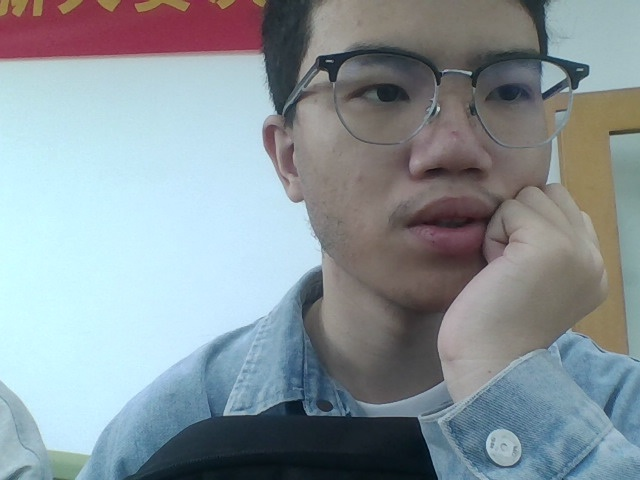

In [4]:
camera_probe_ok = False
probe_capture = None
try:
    probe_capture = open_camera()
    probe_frame = read_camera_frame(probe_capture)
    camera_probe_ok = True
    print("真实摄像头取帧成功：{}x{}。".format(probe_frame.shape[1], probe_frame.shape[0]))
    encoded, image_buffer = cv2.imencode(".jpg", probe_frame)
    if encoded:
        display(Image(data=image_buffer.tobytes()))
except Exception as exc:
    print("真实摄像头取帧失败：{}".format(exc))
finally:
    if probe_capture is not None:
        probe_capture.release()

## 实时识别与实验取证

运行本格后点击“启动实时画面”。做单方块测试时，只保留一个实际方块在 ROI 内，将其余三块移出，再选真实颜色；点击“保存截图”得到同一帧的原图、结果图和四类 Mask。每做一次测试，填写环境或误判说明并点击“记录一次测试”。“停止”会释放摄像头。若当前摄像头仍不能取帧，状态栏会说明原因，且不会生成实验数据。

In [5]:
# 重复运行本格时先停止上一次采集线程，避免摄像头被自己占用。
if "camera_stop_event" in globals():
    camera_stop_event.set()
if "camera_thread" in globals() and camera_thread is not None and camera_thread.is_alive():
    camera_thread.join(timeout=15)

camera_stop_event = threading.Event()
camera_thread = None
latest_lock = threading.Lock()
latest_sample = None
expected_color = None

start_button = widgets.Button(description="启动实时画面", button_style="success")
stop_button = widgets.Button(description="停止")
save_button = widgets.Button(description="保存截图", button_style="info")
record_button = widgets.Button(description="记录一次测试", button_style="warning")
color_buttons = [widgets.Button(description=COLOR_NAMES[name] + "色", tooltip=name) for name in COLOR_ORDER]
note_box = widgets.Textarea(placeholder="记录光照、阴影、反光或背景干扰情况", description="情况说明：", layout=widgets.Layout(width="600px", height="65px"))
status_label = widgets.HTML(value="状态：等待启动。")
result_image = widgets.Image(format="jpeg", layout=widgets.Layout(width="640px"))
masks_image = widgets.Image(format="png", layout=widgets.Layout(width="640px"))


def set_expected(name):
    """设置当前实际方块颜色。"""
    global expected_color
    expected_color = name
    status_label.value = "状态：当前真实颜色为{}色。".format(COLOR_NAMES[name])


for color_name, button in zip(COLOR_ORDER, color_buttons):
    button.on_click(lambda _, name=color_name: set_expected(name))


def camera_worker():
    """在后台读取真实画面并更新 Notebook 内的图像控件。"""
    global latest_sample
    capture = None
    try:
        capture = open_camera()
        last_render = 0.0
        while not camera_stop_event.is_set():
            raw = read_camera_frame(capture)
            annotated, masks, detections = detect_colors(raw)
            grid = make_mask_grid(masks)
            with latest_lock:
                latest_sample = (raw.copy(), annotated.copy(), grid.copy(), list(detections))
            now = time.monotonic()
            if now - last_render >= 0.2:
                ok_result, result_buffer = cv2.imencode(".jpg", annotated, [cv2.IMWRITE_JPEG_QUALITY, 80])
                ok_masks, masks_buffer = cv2.imencode(".png", grid)
                if ok_result and ok_masks:
                    result_image.value = result_buffer.tobytes()
                    masks_image.value = masks_buffer.tobytes()
                    status_label.value = "状态：实时画面正常；当前识别到 {} 个色块；真实颜色：{}。".format(
                        len(detections), COLOR_NAMES.get(expected_color, "未选择"))
                last_render = now
    except Exception as exc:
        status_label.value = "状态：摄像头取帧失败：{}".format(exc)
    finally:
        if capture is not None:
            capture.release()
        camera_stop_event.set()


def start_camera(_):
    """启动后台采集。"""
    global camera_thread, latest_sample
    if camera_thread is not None and camera_thread.is_alive():
        status_label.value = "状态：实时画面已经启动。"
        return
    with latest_lock:
        latest_sample = None
    camera_stop_event.clear()
    status_label.value = "状态：正在连接摄像头，请稍候。"
    camera_thread = threading.Thread(target=camera_worker, daemon=True)
    camera_thread.start()


def stop_camera(_):
    """停止后台采集。"""
    camera_stop_event.set()
    status_label.value = "状态：正在停止摄像头。"


def get_latest_sample():
    """取得一帧真实摄像头样本的独立副本。"""
    with latest_lock:
        if latest_sample is None:
            raise RuntimeError("当前没有真实摄像头画面，不能保存截图或记录测试。")
        raw, annotated, grid, detections = latest_sample
        return raw.copy(), annotated.copy(), grid.copy(), list(detections)


def on_save(_):
    """保存最新真实画面的三张报告截图。"""
    try:
        raw, annotated, grid, _ = get_latest_sample()
        paths = save_evidence(raw, annotated, grid)
        status_label.value = "状态：已保存真实截图：{}。".format("、".join(path.name for path in paths))
    except Exception as exc:
        status_label.value = "状态：截图失败：{}".format(exc)


def on_record(_):
    """把最新真实画面的测试结果写入 CSV。"""
    try:
        _, _, _, detections = get_latest_sample()
        success, detected = record_trial(expected_color, detections, note_box.value)
        status_label.value = "状态：已记录测试；检测颜色={}；结果={}。".format(
            ",".join(detected) or "无", "正确" if success else "错误")
    except Exception as exc:
        status_label.value = "状态：记录失败：{}".format(exc)


start_button.on_click(start_camera)
stop_button.on_click(stop_camera)
save_button.on_click(on_save)
record_button.on_click(on_record)
display(widgets.VBox([
    widgets.HBox([start_button, stop_button, save_button, record_button]),
    widgets.HBox(color_buttons), note_box, status_label,
    widgets.HTML(value="<b>实时识别画面</b>"), result_image,
    widgets.HTML(value="<b>四类 Mask：红、黄、绿、蓝</b>"), masks_image,
]))

## 现场取证记录（2026-10-19）

- 摄像头使用 `/dev/video0`，只调用 `cv2.VideoCapture(0)`；真实画面为 640×480。
- 最初处理整幅画面时，上方机械臂的一处绿色区域偶尔形成面积约 800 像素的额外轮廓。将固定 ROI 设为 `(0, 285, 640, 195)` 后排除了这一背景干扰。
- 加入白色背景后，绿色方块正面在真实截图中的 HSV V 值约为 40～48；原 V 下限 50 只保留了上表面。将绿色 V 下限降至 35 后，同一张真实原图的绿色轮廓面积从约 5,326 增至 17,652 像素。
- 固定白色背景和当前摆放条件下，调整后连续采集 30 帧，30 帧均检测到红、黄、绿、蓝各一个轮廓。这是固定场景的短时稳定性观察，**不能代替至少 40 次不同条件下的单方块测试**。
- [真实原图](evidence/20261019_144812_329070_raw.png)、[识别框与标签](evidence/20261019_144812_329070_result.png)、[四类 Mask](evidence/20261019_144812_329070_masks.png) 来自同一帧，适合放入报告 5.3 节。报告 5.1 节应记录现场最终使用的 HSV 范围，并注明后续光照条件复测结果。

- 当前 ROI 已按要求改为 `None`，后续识别使用整幅画面；上述截图和 30 帧观察仍属于修改前的下方 ROI 条件。


## 实验记录统计

完成真实测试后运行此格，查看记录条数与正确次数。CSV 里已有的行会保留，不自动填充任何测试数据。

In [ ]:
if RECORD_CSV.exists():
    with RECORD_CSV.open("r", newline="", encoding="utf-8-sig") as stream:
        records = list(csv.DictReader(stream))
    correct_count = sum(row.get("result") == "correct" for row in records)
    print("真实测试记录：{} 次；标记正确：{} 次。".format(len(records), correct_count))
    print("CSV：", RECORD_CSV)
else:
    print("尚无真实测试记录；请先完成摄像头测试。")

真实测试记录：12 次；标记正确：12 次。
CSV： /home/jetson/Notebook/5.目标识别/week5_test_records.csv
